<a href="https://colab.research.google.com/github/Prateek0325/Machine-Learning-Projects/blob/main/Healthcare_Risk_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Healthcare Risk Classifier (Diabetes Prediction)**

# **Problem Statement**

Diabetes is a chronic disease that affects millions of people worldwide and can lead to severe health complications if not diagnosed early. Medical factors such as glucose level, Body Mass Index (BMI), age, blood pressure, and insulin levels play a crucial role in determining diabetes risk.

Manual diagnosis based only on observation may result in delayed or inaccurate decisions.

The objective of this project is to build a **classification-based Machine Learning model** to predict whether a patient may have diabetes using medical attributes and to identify the most important factors influencing diabetes risk.

# **Objectives of the Project**

* Understand patterns related to diabetes occurrence

* Perform basic data preprocessing

* Conduct minimal but meaningful Exploratory Data Analysis (EDA)

* Build classification-based machine learning models

* Evaluate model performance using classification metrics

* Identify key medical features influencing diabetes prediction

In [ ]:
#Uploading file
from google.colab import files
upload = files.upload()

Saving diabetes.csv to diabetes.csv


In [ ]:
#Loading/Reading the Dataset

import pandas as pd
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
#importing libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier

**Diabetes Outcome Distribution**

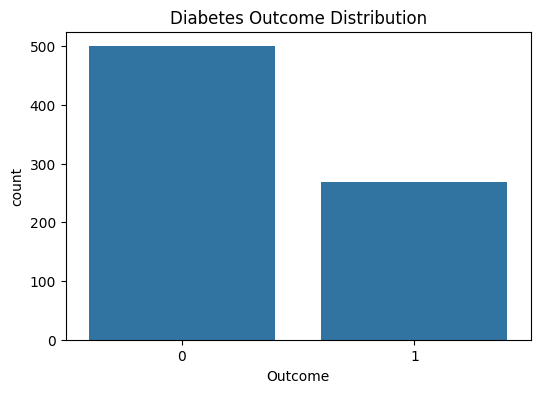

In [ ]:

plt.figure(figsize=(6,4))
sns.countplot(x='Outcome', data=df)
plt.title('Diabetes Outcome Distribution')
plt.show()


**Glucose vs Outcome**

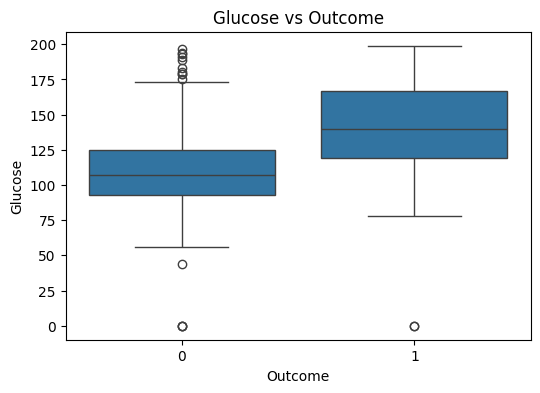

In [ ]:

plt.figure(figsize=(6,4))
sns.boxplot(x='Outcome', y='Glucose', data=df)
plt.title('Glucose vs Outcome')
plt.show()


**BMI vs Outcome**

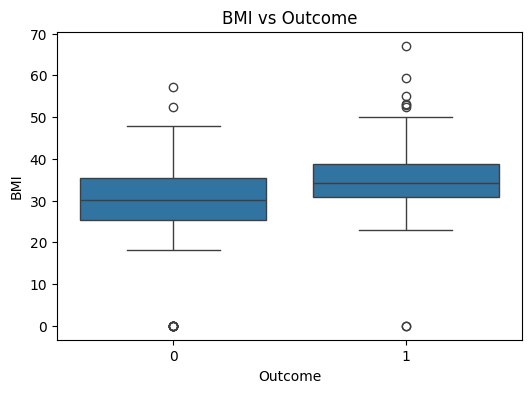

In [ ]:
plt.figure(figsize=(6,4))
sns.boxplot(x='Outcome', y='BMI', data=df)
plt.title('BMI vs Outcome')
plt.show()


**Age VS Outcome**

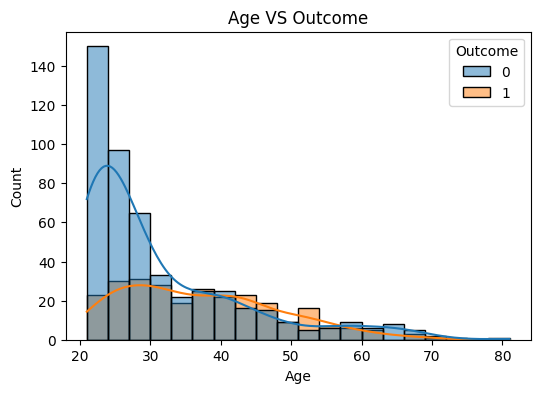

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(data=df, x='Age', hue='Outcome', bins=20, kde=True)
plt.title('Age VS Outcome')
plt.show()


**Data Cleaning**

In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
#Checking missing values
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


**Feature and Target**

In [ ]:
x = df.drop('Outcome', axis=1)
y = df['Outcome']

**Scaling Numerical Features**

In [ ]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)


**Train-test split**

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x_scaled, y, test_size=0.2, random_state=42
)

**Training Logistic Regression Model**

In [ ]:
model_lg = LogisticRegression()
model_lg.fit(x_train, y_train)

y_pred_lg = model_lg.predict(x_test)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lg))
print("Classification Report:\n", classification_report(y_test, y_pred_lg))

Logistic Regression Accuracy: 0.7532467532467533
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.80      0.81        99
           1       0.65      0.67      0.66        55

    accuracy                           0.75       154
   macro avg       0.73      0.74      0.73       154
weighted avg       0.76      0.75      0.75       154



**Training Decicsion Tree model**

In [ ]:
model_dt = DecisionTreeClassifier(criterion='gini', max_depth=3)
model_dt.fit(x_train, y_train)

y_pred_dt = model_dt.predict(x_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print(print("Classification Report:\n", classification_report(y_test, y_pred_dt)))

Decision Tree Accuracy: 0.7597402597402597
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.84      0.82        99
           1       0.68      0.62      0.65        55

    accuracy                           0.76       154
   macro avg       0.74      0.73      0.73       154
weighted avg       0.76      0.76      0.76       154

None


**Train Random Forest Model**

In [ ]:
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_rf.fit(x_train, y_train)
y_pred_rf = model_rf.predict(x_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.7272727272727273
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.79      0.79        99
           1       0.62      0.62      0.62        55

    accuracy                           0.73       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154



# **Confusuin Matrix**

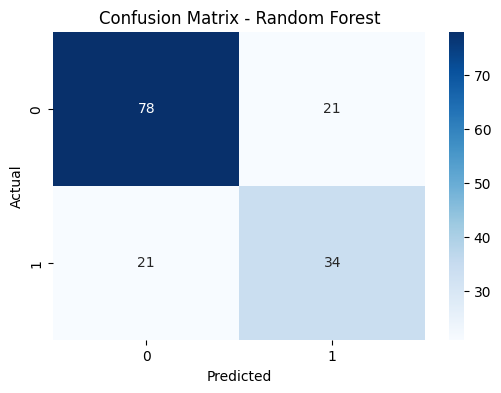

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

# Plot confusion matrix as heatmap
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# **Feature Importance**

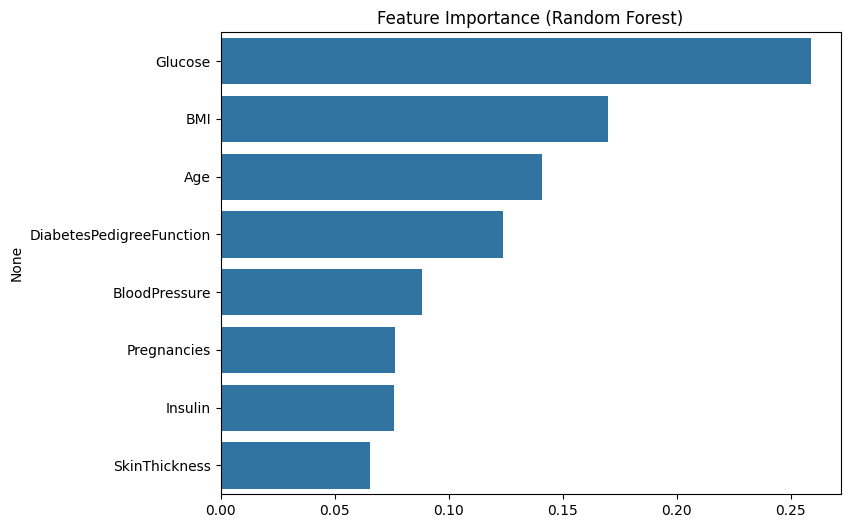

In [ ]:
importances = model_rf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8,6))
sns.barplot(x=importances[indices], y=x.columns[indices])
plt.title('Feature Importance (Random Forest)')
plt.show()
